# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

### ✅ Solution – Load `bert-base-uncased`

`attn_implementation="eager"` is set when loading so the model can return its attention weights.

In [6]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval();

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### ✅ Solution – Task 1: Layers and attention heads per layer

BERT uses different config names than DistilBERT: `num_hidden_layers` and `num_attention_heads`.

In [7]:
num_layers = bert_model.config.num_hidden_layers
heads_per_layer = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", heads_per_layer)
print("Hidden size:", bert_model.config.hidden_size)

Transformer layers: 12
Attention heads per layer: 12
Hidden size: 768


### ✅ Solution – Task 2: Total number of attention heads

In [8]:
total_heads = num_layers * heads_per_layer

print(f"Total attention heads: {num_layers} layers x {heads_per_layer} heads = {total_heads}")

Total attention heads: 12 layers x 12 heads = 144


### ✅ Solution – Task 3: Attention weights from layer 3, head 2

`outputs.attentions` is a tuple with one tensor per layer, each of shape `(batch, heads, tokens, tokens)`.
Python indexing starts at 0, so the **third layer** is index `2` and the **second head** is index `1`.

In [9]:
task_sentence = "Transformers use self-attention to understand language."

task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

with torch.no_grad():
    task_outputs = bert_model(**task_inputs, output_attentions=True)

print("Number of layers returned:", len(task_outputs.attentions))
print("Shape of one layer's attention:", task_outputs.attentions[0].shape)

# Third layer (index 2), first sentence in the batch (index 0), second head (index 1)
layer3_head2 = task_outputs.attentions[2][0, 1]

print("Tokens:", task_tokens)
print("Attention shape:", layer3_head2.shape)
print("Attention weights (layer 3, head 2):")
torch.set_printoptions(precision=3, sci_mode=False, linewidth=200)
print(layer3_head2)

Number of layers returned: 12
Shape of one layer's attention: torch.Size([1, 12, 11, 11])
Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention shape: torch.Size([11, 11])
Attention weights (layer 3, head 2):
tensor([[0.732, 0.008, 0.011, 0.006, 0.017, 0.007, 0.010, 0.012, 0.006, 0.039, 0.155],
        [0.889, 0.005, 0.034, 0.000, 0.003, 0.005, 0.001, 0.001, 0.000, 0.005, 0.057],
        [0.143, 0.569, 0.005, 0.035, 0.041, 0.068, 0.090, 0.000, 0.005, 0.009, 0.034],
        [0.340, 0.073, 0.002, 0.000, 0.202, 0.081, 0.064, 0.026, 0.002, 0.028, 0.183],
        [0.143, 0.070, 0.071, 0.639, 0.012, 0.013, 0.003, 0.003, 0.014, 0.009, 0.022],
        [0.113, 0.545, 0.012, 0.020, 0.111, 0.010, 0.072, 0.000, 0.000, 0.016, 0.100],
        [0.084, 0.022, 0.622, 0.008, 0.009, 0.194, 0.011, 0.007, 0.001, 0.014, 0.027],
        [0.434, 0.005, 0.002, 0.022, 0.012, 0.003, 0.330, 0.002, 0.055, 0.053, 0.082],
        [0.051, 0.001, 0.4

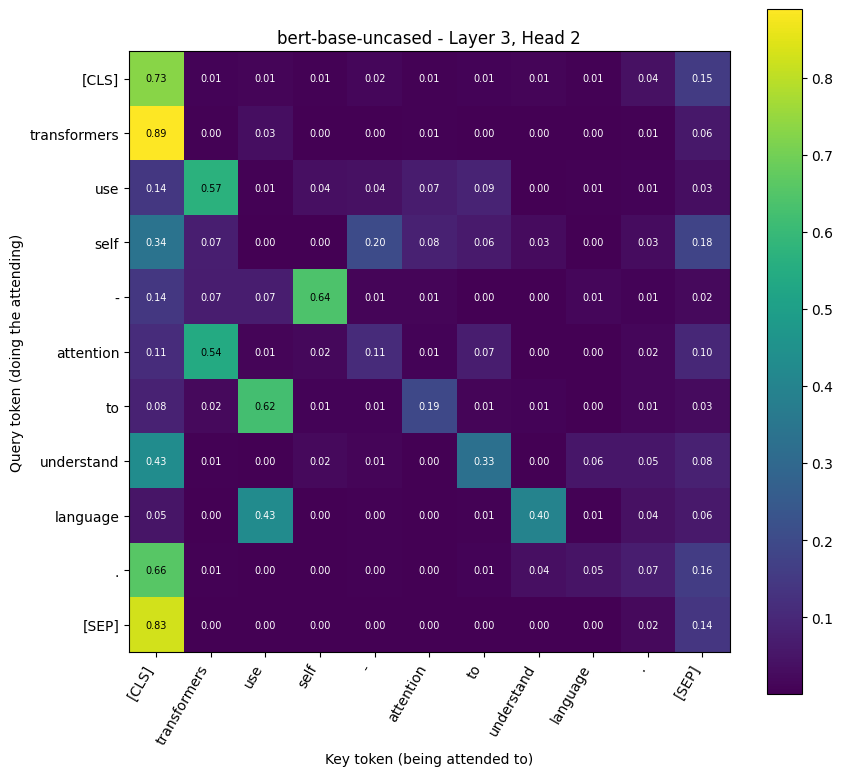

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(layer3_head2.numpy(), cmap="viridis")

ax.set_xticks(range(len(task_tokens)))
ax.set_yticks(range(len(task_tokens)))
ax.set_xticklabels(task_tokens, rotation=60, ha="right")
ax.set_yticklabels(task_tokens)
ax.set_xlabel("Key token (being attended to)")
ax.set_ylabel("Query token (doing the attending)")
ax.set_title("bert-base-uncased - Layer 3, Head 2")

for i in range(len(task_tokens)):
    for j in range(len(task_tokens)):
        value = layer3_head2[i, j].item()
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                color="black" if value > 0.5 else "white")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [11]:
# Each row is a probability distribution (softmax), so every row sums to 1
print("Row sums:", layer3_head2.sum(dim=1))

# Which token does each token attend to the most?
for i, token in enumerate(task_tokens):
    j = layer3_head2[i].argmax().item()
    print(f"{token:>12} -> {task_tokens[j]:<12} ({layer3_head2[i, j].item():.3f})")

Row sums: tensor([1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000, 1.000])
       [CLS] -> [CLS]        (0.732)
transformers -> [CLS]        (0.889)
         use -> transformers (0.569)
        self -> [CLS]        (0.340)
           - -> self         (0.639)
   attention -> transformers (0.545)
          to -> use          (0.622)
  understand -> [CLS]        (0.434)
    language -> use          (0.429)
           . -> [CLS]        (0.658)
       [SEP] -> [CLS]        (0.828)


### ✅ Solution – Task 4: What do the rows and columns of the attention matrix represent?

The matrix has shape **11 × 11** because the sentence becomes 11 tokens:
`[CLS] transformers use self - attention to understand language . [SEP]`.

- **Rows = query tokens** – the token that is *doing the attending*. Row *i* answers the question: *"When BERT builds the new representation of token i, how much does it look at each token in the sentence?"*
- **Columns = key tokens** – the token that is *being attended to*. Column *j* shows how much attention every token gives to token *j*.
- **Each value** `attention[i, j]` is the weight token *i* gives to token *j*. The weights come from a softmax, so **every row sums to 1** (verified above). The new vector of token *i* is the weighted sum of the (value) vectors of all tokens using the weights in row *i*.
- The matrix is **not symmetric**: `attention[i, j]` ≠ `attention[j, i]`. For example, *use → transformers* is **0.569**, but *transformers → use* is only **0.034**.

**What this head (layer 3, head 2) does in this sentence**

| Query token (row) | Most-attended token (column) | Weight |
|---|---|---|
| use | transformers | 0.569 |
| attention | transformers | 0.545 |
| to | use | 0.622 |
| language | use (0.429) / understand (0.398) | – |
| - | self | 0.639 |
| [CLS], transformers, ., [SEP] | [CLS] | 0.66 – 0.89 |

- Several rows connect words that are related in the sentence structure: the verb **use** looks at its subject **transformers**, **to** looks back at **use**, and the object **language** looks at the verbs **use** and **understand**. The hyphen in **self-attention** looks at **self**, joining the two parts of the word.
- Many tokens put most of their weight on **[CLS]** (first column). This is a common pattern in BERT: when a head has no useful relation to find for a token, it puts the attention on a special token ([CLS] / [SEP]) as a "no-op".
- BERT has 144 heads (Task 2), and each one learns a different pattern; this one mostly links words to related earlier words in the sentence.